In [ ]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte
from skimage import data
from skimage.filters import unsharp_mask
from skimage import filters as ski
from skimage import filters, exposure, morphology

In [ ]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte
from skimage import data
from skimage.filters import unsharp_mask
from skimage import filters as ski
from skimage import filters, exposure, morphology

In [ ]:
!pip install numpy opencv-python scikit-image Pillow scipy

In [ ]:
from google.colab import  files
uploaded = files.upload()

Saving HI_CUBE_z_7.391.fits to HI_CUBE_z_7.391.fits


In [ ]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import os

# Load the FITS cube
hdul = fits.open('HI_CUBE_z_7.391.fits')  # Replace with actual filename
data_cube = np.squeeze(hdul[0].data)     # Remove singleton dims if needed
print("Cube shape:", data_cube.shape)    # Should be (Z, X, Y) or (256, 256, 256)

# Create output folder if it doesn't exist
output_folder = 'raw_slices'
os.makedirs(output_folder, exist_ok=True)

# Loop through all slices (assume Z is the first axis)
for z in range(data_cube.shape[0]):
    slice_2d = data_cube[z, :, :]  # Get slice at depth z

    # Save the image
    plt.imsave(f"{output_folder}/raw{z:03d}.png", slice_2d, cmap='gray')

print(f"✅ All {data_cube.shape[0]} raw slices saved to '{output_folder}' folder.")


Cube shape: (256, 256, 256)
✅ All 256 raw slices saved to 'raw_slices' folder.


<function matplotlib.pyplot.show(close=None, block=None)>

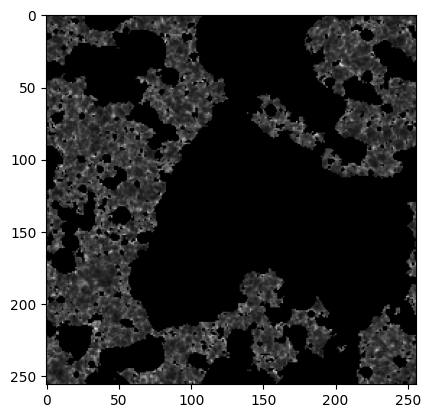

In [ ]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
hdul2 = fits.open('HI_CUBE_z_7.391.fits')
cosmo_data2 = np.squeeze(hdul2[0].data)
cosmo_1 = cosmo_data2[5, :, :]
cosmo_1.shape
plt.imshow(cosmo_1, cmap='grey')
plt.show


In [ ]:
cosmo_data2.shape

(256, 256, 256)

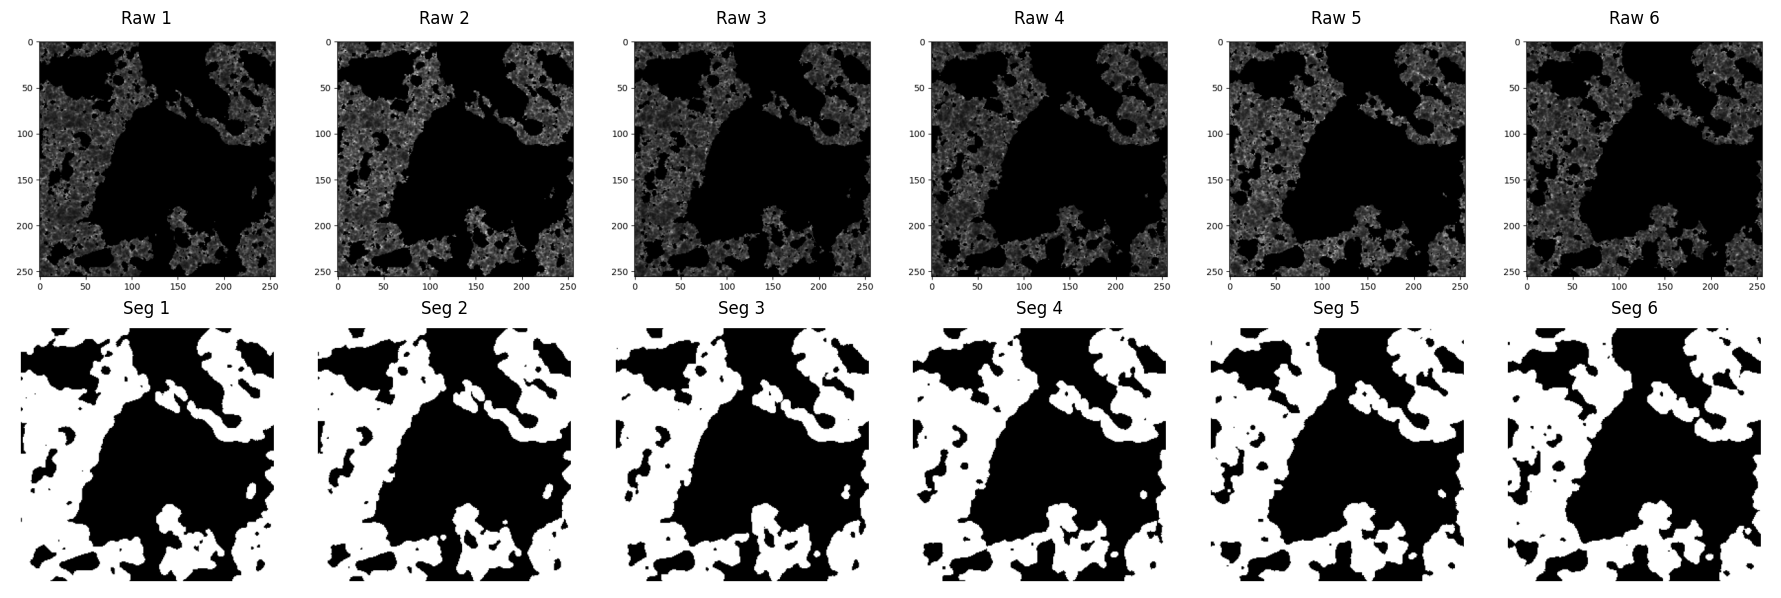

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Load images from files
raw_images = [mpimg.imread('raw1.png'), mpimg.imread('raw2.png'),
              mpimg.imread('raw3.png'), mpimg.imread('raw4.png'),
              mpimg.imread('raw5.png'), mpimg.imread('raw6.png')]

seg_images = [mpimg.imread('seg1.png'), mpimg.imread('seg2.png'),
              mpimg.imread('seg3.png'), mpimg.imread('seg4.png'),
              mpimg.imread('seg5.png'), mpimg.imread('seg6.png')]

# Plot
fig, axs = plt.subplots(2, 6, figsize=(18, 6))

# First row: Raw images
for i in range(6):
    axs[0, i].imshow(raw_images[i], cmap='gray')
    axs[0, i].set_title(f'Raw {i+1}')
    axs[0, i].axis('off')

# Second row: Segmented images
for i in range(6):
    axs[1, i].imshow(seg_images[i], cmap='gray')
    axs[1, i].set_title(f'Seg {i+1}')
    axs[1, i].axis('off')

plt.tight_layout()
plt.show()


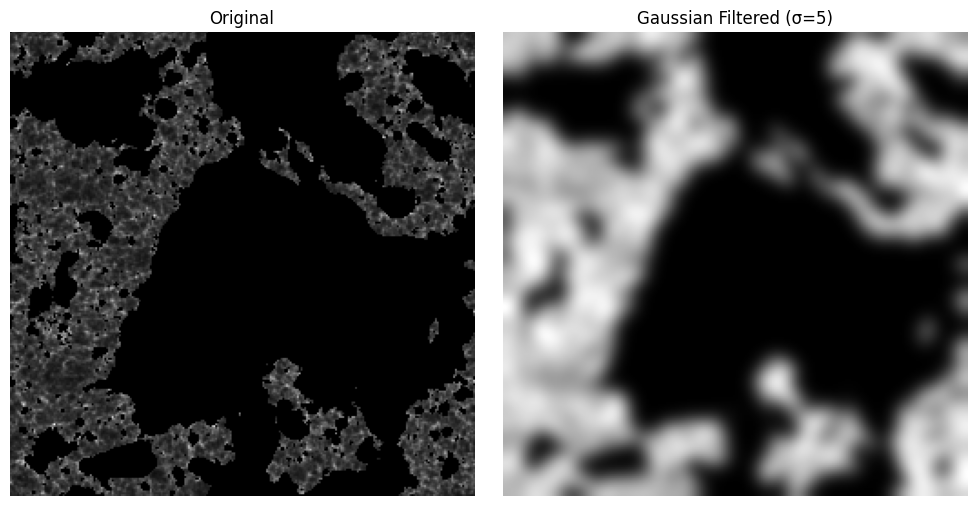

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import data, img_as_float

# Load a sample image (you can replace this with your own image)
image = cosmo_1  # grayscale image

# Apply Gaussian filter
sigma = 5  # standard deviation, controls amount of blur
smoothed_image = gaussian_filter(image, sigma=sigma)

# Display
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap='grey')
axes[0].set_title("Original")
axes[1].imshow(smoothed_image, cmap='grey')
axes[1].set_title(f"Gaussian Filtered (σ={sigma})")

for ax in axes:
    ax.axis('off')
plt.savefig("Image LT.png", dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()


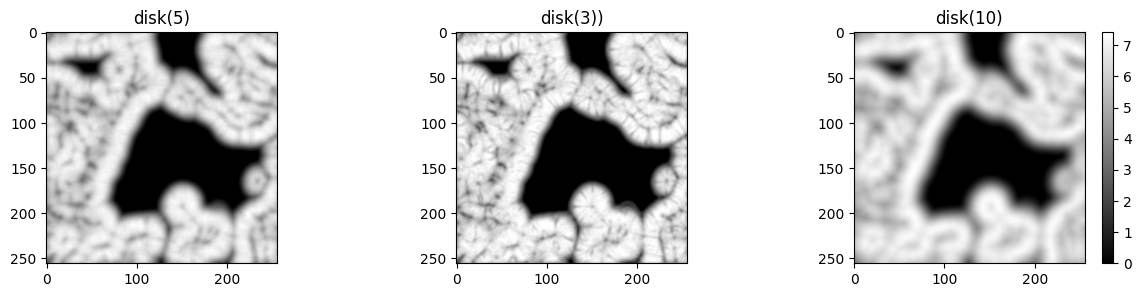

In [ ]:
import numpy as np

from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte

Cosmo_Entropy = img_as_ubyte(exposure.rescale_intensity(smoothed_image))
entropy_map1 = entropy(Cosmo_Entropy, disk(5))
entropy_map2 = entropy(Cosmo_Entropy, disk(3))
entropy_map3 = entropy(Cosmo_Entropy, disk(10))
plt.figure(figsize= (15,3))


plt.subplot(1,3,1); plt.imshow(entropy_map1, cmap='gray')
plt.title("disk(5)")
plt.subplot(1,3,2); plt.imshow(entropy_map2, cmap='gray')
plt.title("disk(3))")
plt.subplot(1,3,3); plt.imshow(entropy_map3,cmap='gray')
plt.title("disk(10)")

plt.colorbar()

plt.show()

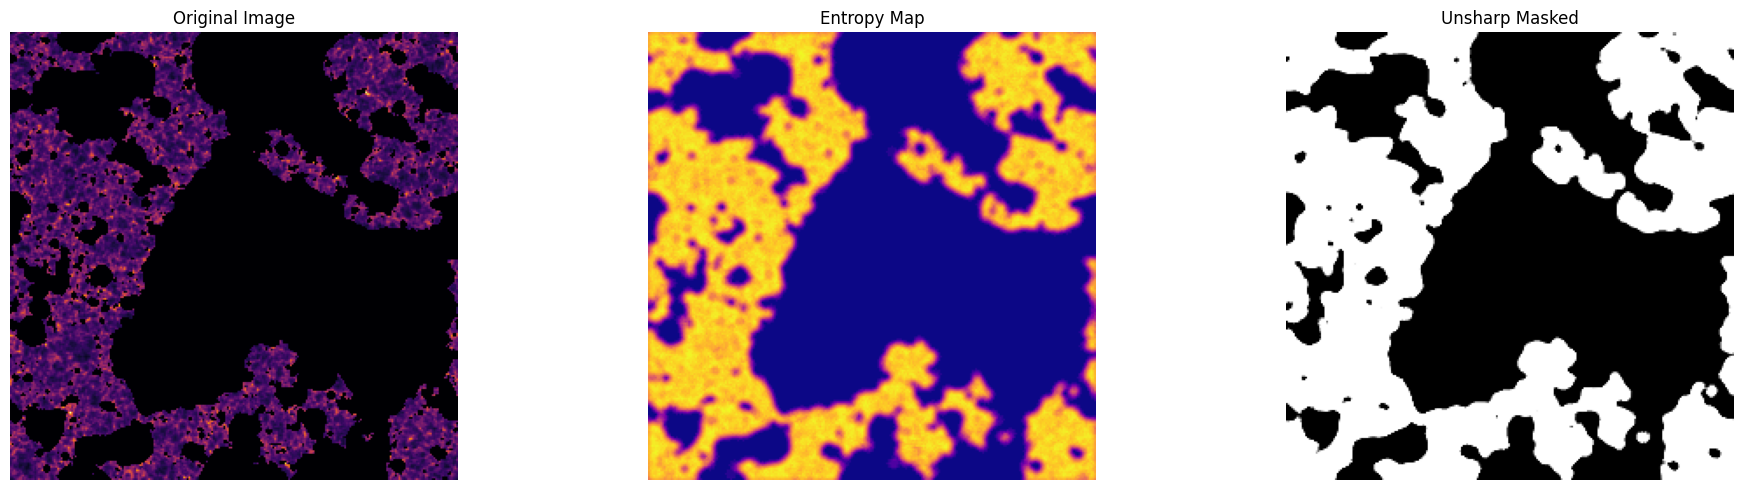

In [ ]:
image1 = cosmo_1  # Dummy brightness temperature map

# --- 2. Apply Local Entropy ---
entropy_input = img_as_ubyte(exposure.rescale_intensity(image1))
entropy_map1 = entropy(entropy_input, morphology.disk(3))

# --- 3. Apply Unsharp Masking to sharpen edges ---
sharpened1 = unsharp_mask(entropy_map1, radius=20, amount=1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].imshow(image1, cmap='inferno')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map1, cmap='plasma')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened1, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

plt.tight_layout()
plt.show()

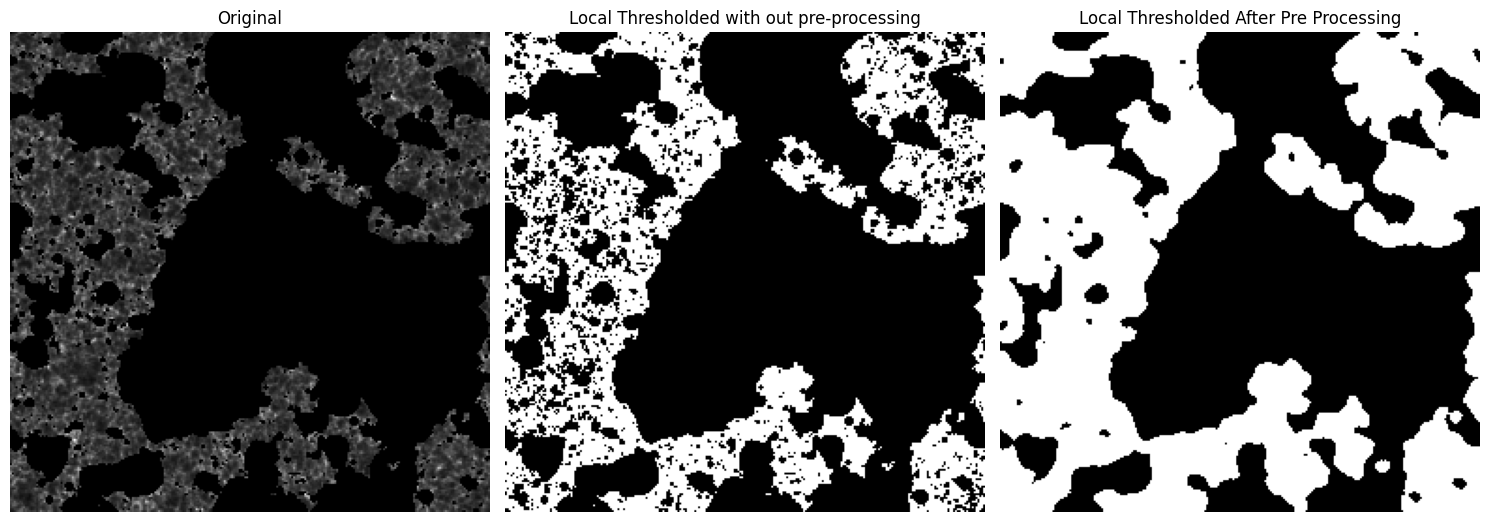

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io  # or use your cosmo_1

# Assuming cosmo_1 is your 2D image from a z-slice
# Make sure it's float type for proper thresholding
image1 = cosmo_1.astype(float)
unsharp1 = sharpened1.astype(float)

# Set block size for local thresholding (must be odd)
block_size = 121  # you can also use it with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(image1, block_size, offset=offset)
local_thresh2 = threshold_local(unsharp1, block_size, offset=offset)

# Apply threshold: pixels > local threshold → foreground (True)
binary_local = image1 > local_thresh
binary_local21 = unsharp1 > local_thresh2
# Plot original and thresholded image
fig, ax = plt.subplots(1, 3, figsize=(15, 10))
plt.gray()

ax[0].imshow(image1)
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded with out pre-processing")

ax[2].imshow(binary_local21)
ax[2].set_title("Local Thresholded After Pre Processing")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


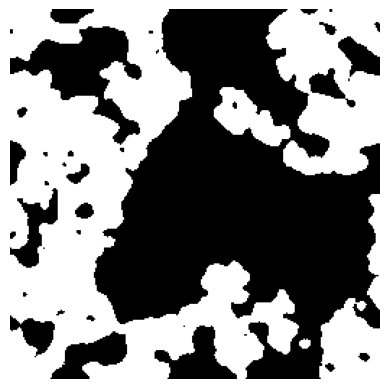

In [ ]:
plt.imshow(binary_local21, cmap='gray')
plt.axis('off')
plt.show()

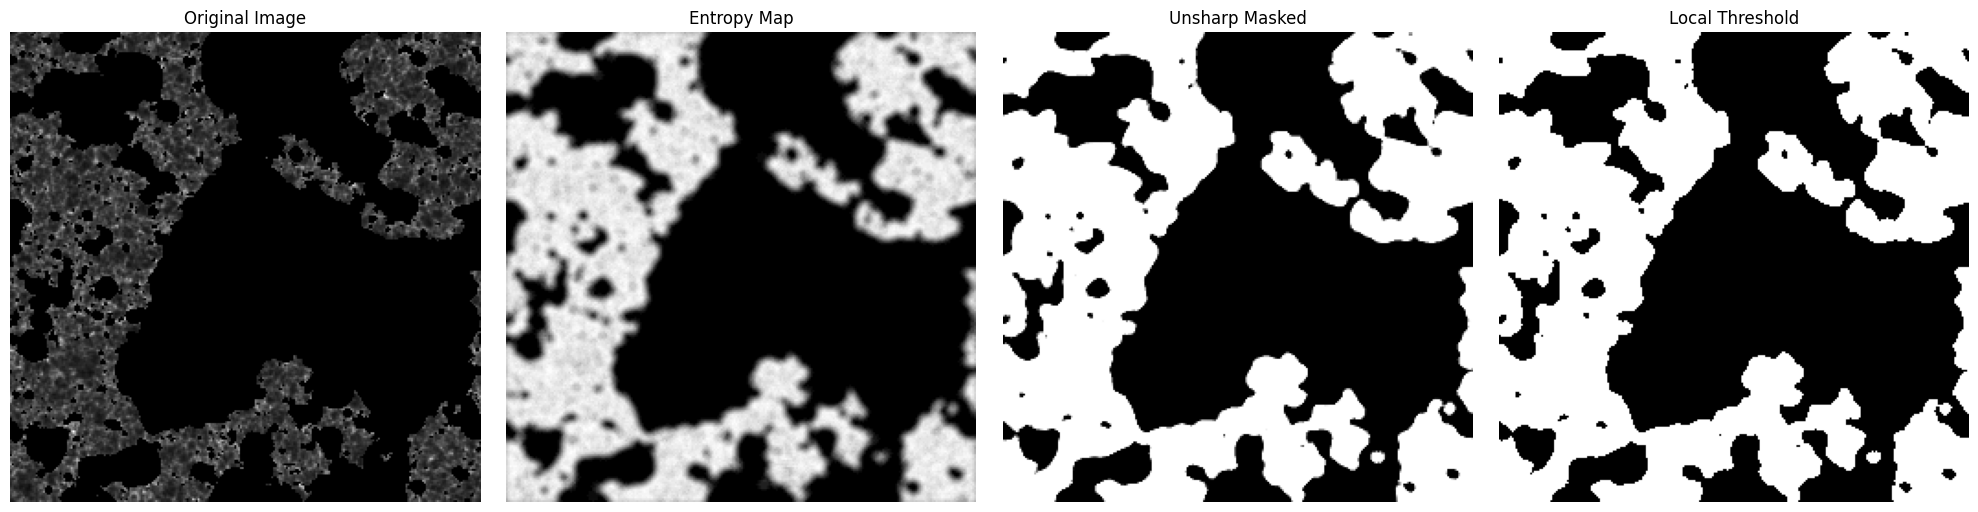

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(image1, cmap='grey')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map1, cmap='gray')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened1, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

axes[3].imshow(binary_local21, cmap='gray')
axes[3].set_title("Local Threshold")
axes[3].axis('off')

plt.tight_layout()
plt.show()

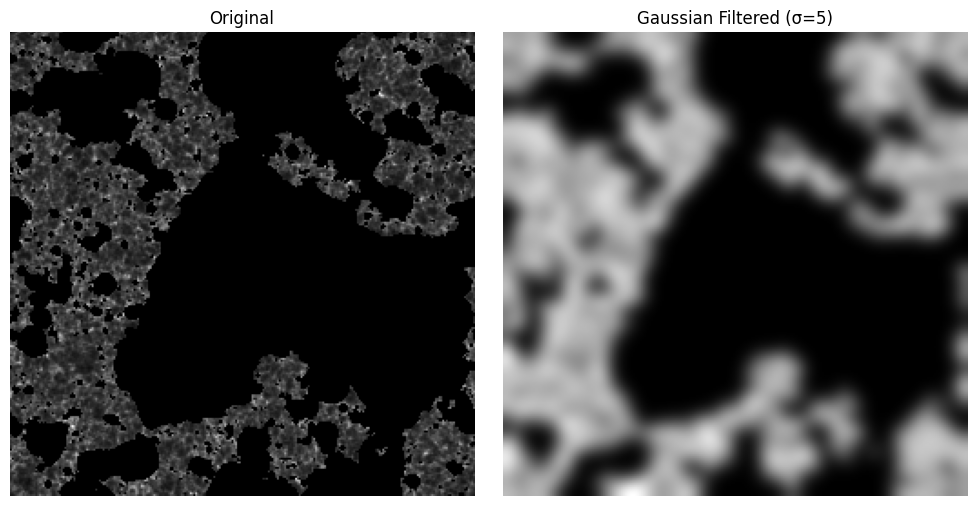

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import data, img_as_float

# Load a sample image (you can replace this with your own image)
image = cosmo_1  # grayscale image

# Apply Gaussian filter
sigma = 5  # standard deviation, controls amount of blur
smoothed_image = gaussian_filter(image, sigma=sigma)

# Display
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap='grey')
axes[0].set_title("Original")
axes[1].imshow(smoothed_image, cmap='grey')
axes[1].set_title(f"Gaussian Filtered (σ={sigma})")

for ax in axes:
    ax.axis('off')
plt.savefig("Image LT.png", dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()


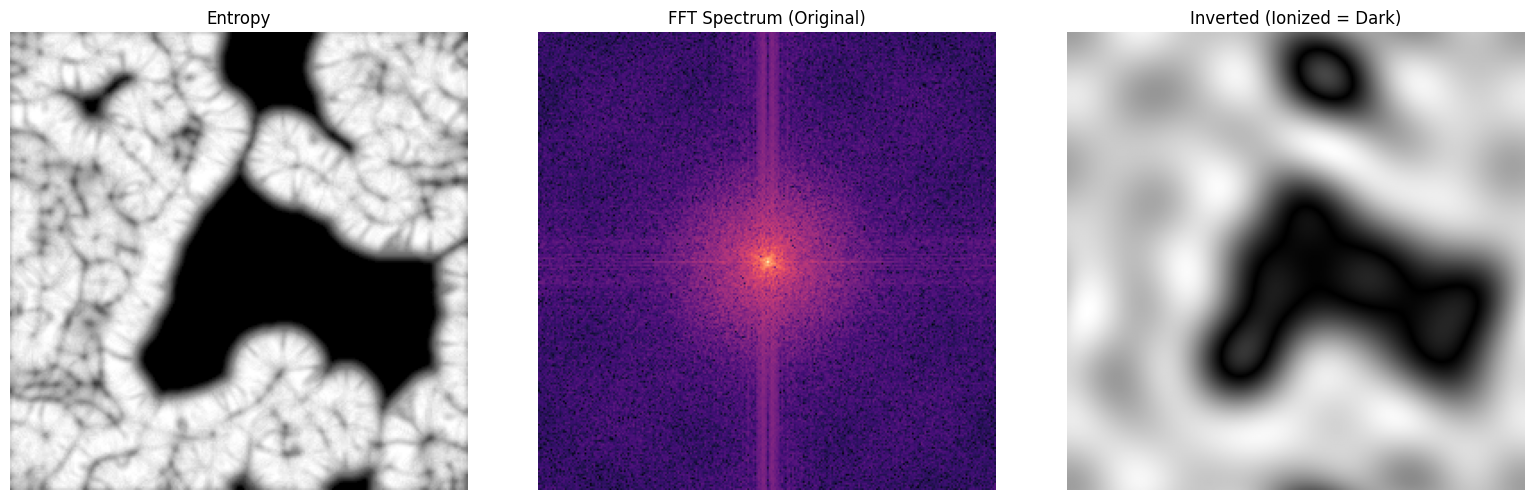

In [ ]:

#FFT FOR ENTROPY

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from skimage.util import invert
from skimage.exposure import rescale_intensity

def fft_low_pass_filter(entropy_map2, radius=20):
    # Step 1: Forward 2D FFT
    f_image = fft2(entropy_map2)
    f_shift = fftshift(f_image)  # Shift zero-freq to center

    # Step 2: Create circular low-pass filter mask
    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    mask_area = (x - ccol)**2 + (y - crow)**2 <= radius**2
    mask = np.zeros_like(entropy_map2)
    mask[mask_area] = 1

    # Step 3: Apply mask
    f_filtered = f_shift * mask

    # Step 4: Inverse FFT to get denoised image
    f_ishift = ifftshift(f_filtered)
    denoised = np.abs(ifft2(f_ishift))

    return denoised, f_shift, f_filtered

# ---- Step 1: Apply FFT Filter ----
denoised_img, fft_original, fft_filtered = fft_low_pass_filter(entropy_map2, radius=5)

# ---- Step 2: Normalize and Invert ----
denoised_img_normE2 = rescale_intensity(denoised_img, in_range='image', out_range=(0, 1))
inverted_imgE2 = invert(denoised_img_normE2)

# ---- Step 3: Plot All Results ----
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(entropy_map2, cmap='gray')
plt.title("Entropy")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(fft_original)), cmap='magma')
plt.title("FFT Spectrum (Original)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(denoised_img_normE2, cmap='gray')
plt.title("Denoised (Normalized)")
plt.axis('off')



plt.title("Inverted (Ionized = Dark)")
plt.axis('off')

plt.tight_layout()
plt.show()


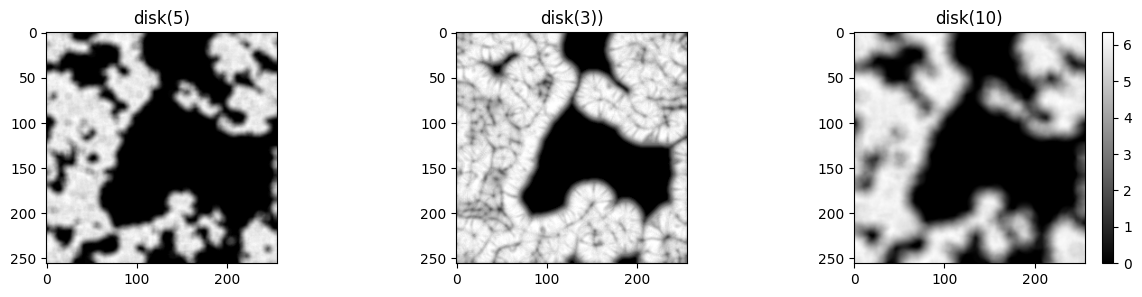

In [ ]:
import numpy as np

from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte

Cosmo_Entropy = img_as_ubyte(exposure.rescale_intensity(cosmo_1))
entropy_map1 = entropy(Cosmo_Entropy, disk(5))
entropy_map21 = entropy(Cosmo_Entropy, disk(3))
entropy_map3 = entropy(Cosmo_Entropy, disk(10))
plt.figure(figsize= (15,3))


plt.subplot(1,3,1); plt.imshow(entropy_map1, cmap='gray')
plt.title("disk(5)")
plt.subplot(1,3,2); plt.imshow(entropy_map2, cmap='gray')
plt.title("disk(3))")
plt.subplot(1,3,3); plt.imshow(entropy_map3,cmap='gray')
plt.title("disk(10)")

plt.colorbar()

plt.show()

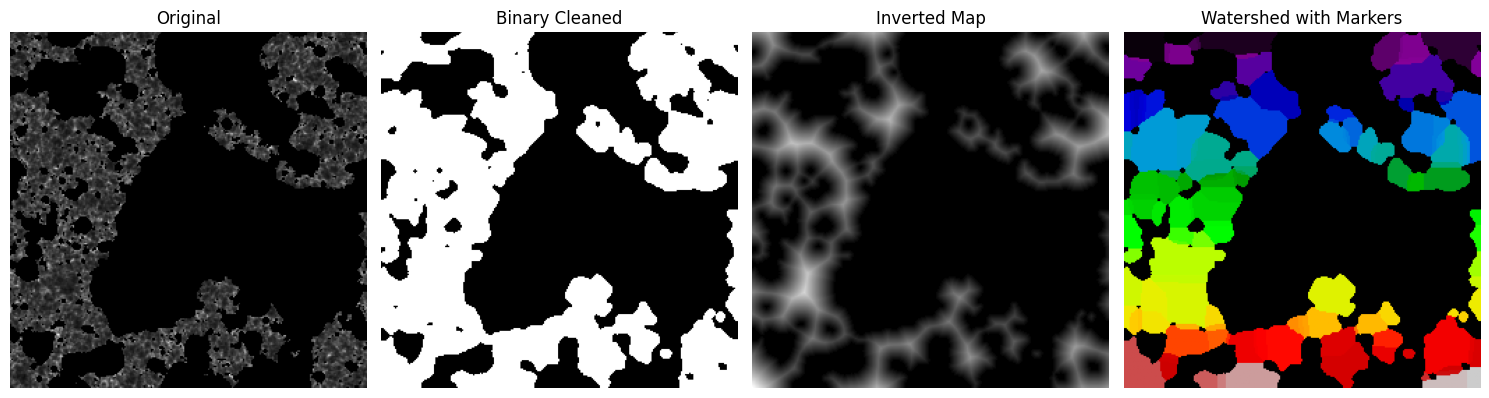

In [ ]:
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.morphology import remove_small_objects, local_maxima
from skimage.measure import label
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

# Step 1: Clean binary mask
binary_clean = remove_small_objects(sharpened1.astype(bool), min_size=50)

# Step 2: Distance transform
distance = ndi.distance_transform_edt(binary_clean)

# Step 3: Local maxima mask
local_maxi = local_maxima(distance * binary_clean)

# Step 4: Label foreground markers
markers = label(local_maxi)

# Step 5: Apply watershed
labels_ws = watershed(-distance, markers, mask=binary_clean)

# Step 6: Display results
fig, ax = plt.subplots(1, 4, figsize=(15, 5))
ax[0].imshow(cosmo_1, cmap='gray')
ax[0].set_title('Original')

ax[1].imshow(binary_clean, cmap='gray')
ax[1].set_title('Binary Cleaned')

ax[2].imshow(distance, cmap='gray')
ax[2].set_title('Inverted Map')


ax[3].imshow(labels_ws, cmap='nipy_spectral')
ax[3].set_title('Watershed with Markers')

for a in ax:
    a.set_axis_off()

plt.tight_layout()
plt.show()


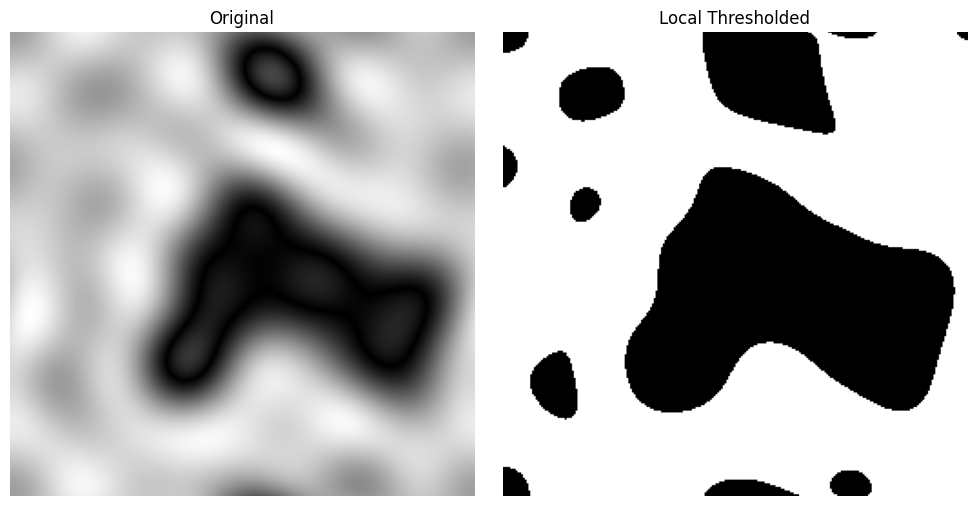

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io  # or use your cosmo_1

# Assuming cosmo_1 is your 2D image from a z-slice
# Make sure it's float type for proper thresholding
image3 = denoised_img_normE2.astype(float)


# Set block size for local thresholding (must be odd)
block_size = 511 # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local( denoised_img_normE2, block_size, offset=offset)


# Apply threshold: pixels > local threshold → foreground (True)
binary_local = denoised_img_normE2 > local_thresh

# Plot original and thresholded image
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
plt.gray()

ax[0].imshow(denoised_img_normE2 , cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


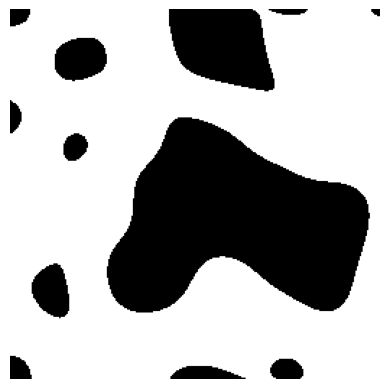

In [ ]:
plt.imshow(binary_local, cmap='gray')
plt.axis('off')
plt.show()

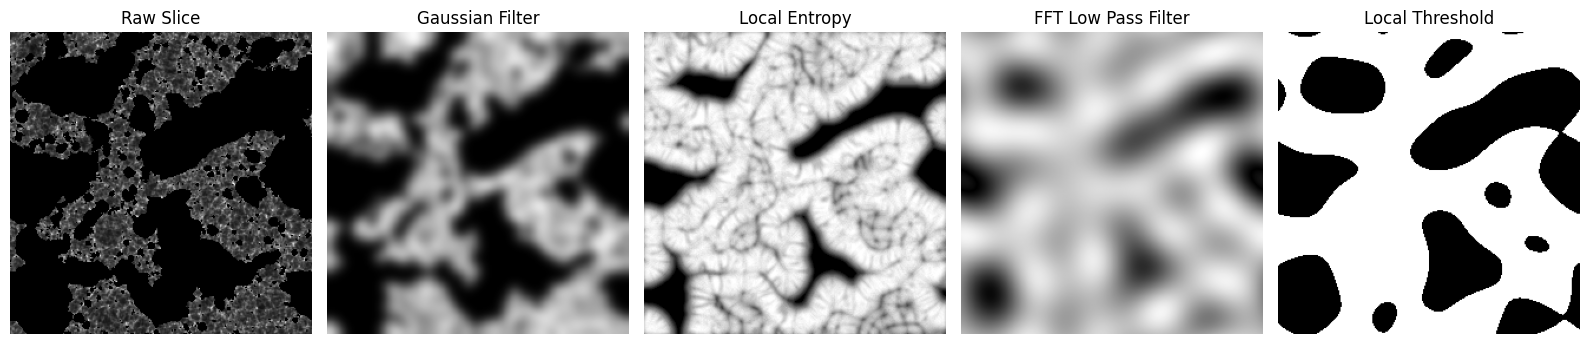

In [ ]:
  fig, axes = plt.subplots(1, 5, figsize=(16, 9))
ax = axes.ravel()

ax[0].imshow(cosmo_1, cmap='gray')
ax[0].set_title("Raw Slice")
ax[0].axis('off')

ax[1].imshow(smoothed_image, cmap='gray')
ax[1].set_title("Gaussian Filter")
ax[1].axis('off')

ax[2].imshow(entropy_map2, cmap='gray')
ax[2].set_title("Local Entropy")
ax[2].axis('off')

ax[3].imshow(denoised_img_normE2, cmap='gray')
ax[3].set_title("FFT Low Pass Filter")
ax[3].axis('off')

ax[4].imshow(binary_local, cmap='gray')
ax[4].set_title("Local Threshold")
ax[4].axis('off')



plt.tight_layout()
plt.show()

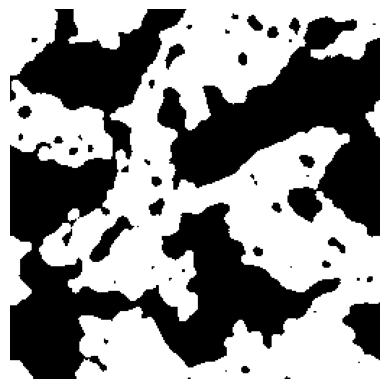

In [ ]:
from skimage.morphology import remove_small_objects

# binary_segmented is your binary mask (e.g. after thresholding)
cleaned = remove_small_objects(binary_local21.astype(bool), min_size=100)

# Optional: convert back to float if needed
cleaned = cleaned.astype(float)

plt.imshow(cleaned, cmap='gray')
plt.axis('off')
plt.show()


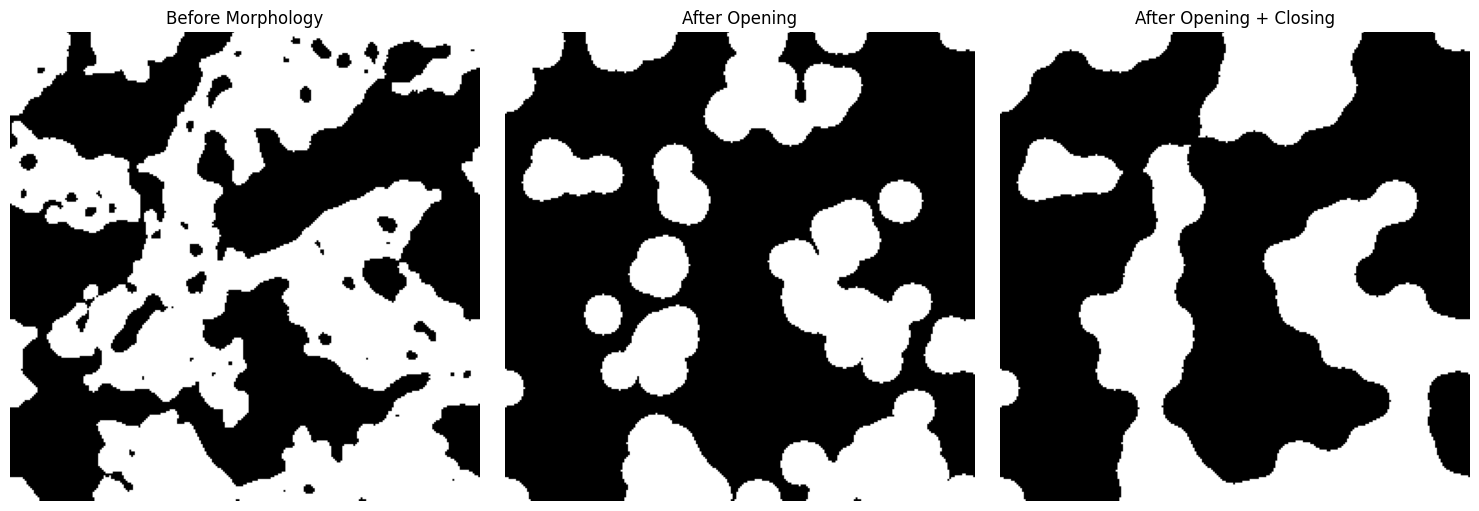

In [ ]:
from skimage.morphology import opening, closing, disk
import matplotlib.pyplot as plt
# Define structuring element size
selem = disk(10)  # Change the radius as needed, like 1, 3, 5, etc.

# Opening: removes small white noise
opened = opening(binary_local21, selem)

# Closing: fills small black holes inside regions
closed = closing(opened, selem)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(binary_local21, cmap='gray')
ax[0].set_title('Before Morphology')

ax[1].imshow(opened, cmap='gray')
ax[1].set_title('After Opening')

ax[2].imshow(closed, cmap='gray')
ax[2].set_title('After Opening + Closing')

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


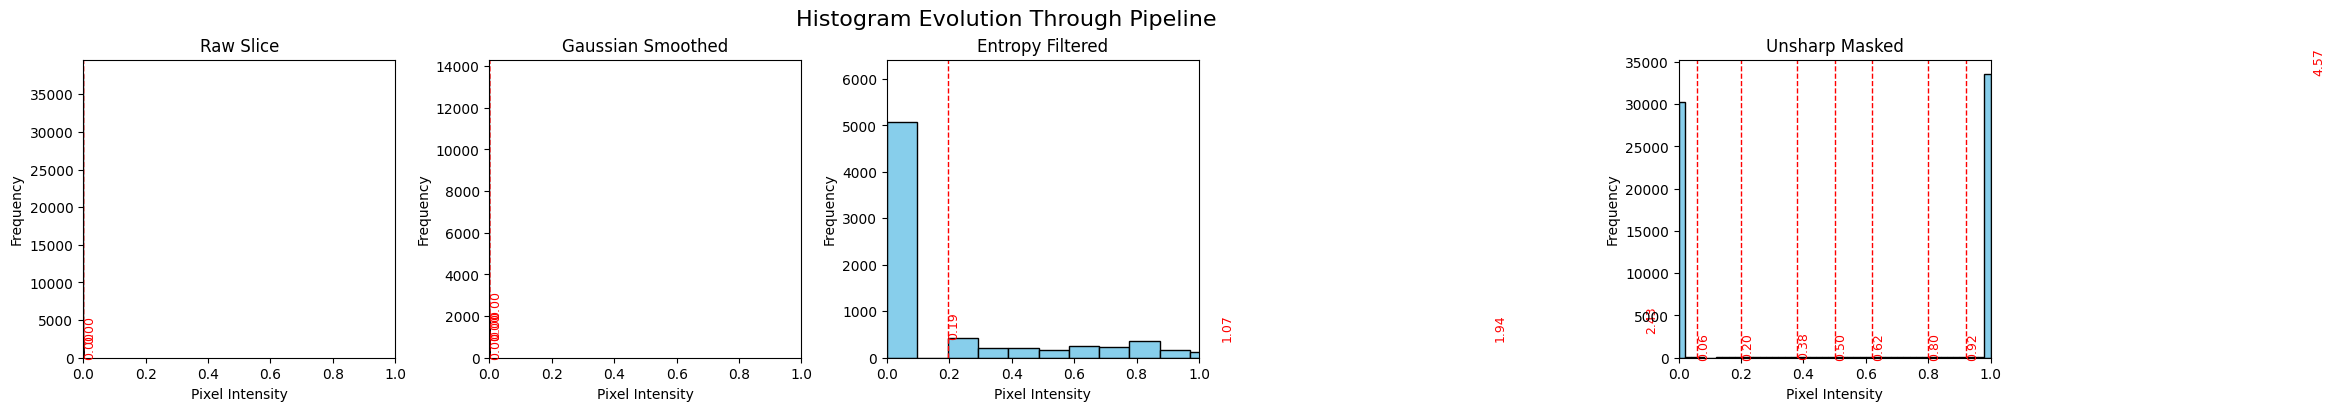

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# Assuming the following variables are already defined:
# cosmo1         → raw slice
# smoothed_image → after Gaussian
# entropy_map_2  → after entropy filtering
# sharpened_1    → after unsharp masking

# Create a list of images and labels
images = [cosmo_1, smoothed_image, entropy_map2, sharpened1]
titles = ['Raw Slice', 'Gaussian Smoothed', 'Entropy Filtered', 'Unsharp Masked']

# Plot settings
fig, axes = plt.subplots(1, 4, figsize=(20, 4), constrained_layout=True)
bins = np.linspace(0, 1, 100)  # adjust range if your values are different

for ax, img, title in zip(axes, images, titles):
    # Flatten image to 1D
    pixels = img.flatten()

    # Plot histogram
    counts, bins_, _ = ax.hist(pixels, bins= 50, color='skyblue', edgecolor='k')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Frequency")
    ax.set_xlim(0, 1)

    # Find and mark peaks
    peak_indices, _ = find_peaks(counts, distance=5)
    for idx in peak_indices:
        peak_x = bins_[idx]
        ax.axvline(x=peak_x, color='red', linestyle='--', linewidth=1)
        ax.text(peak_x, counts[idx] + 50, f'{peak_x:.2f}', color='red', fontsize=9, rotation=90)

plt.suptitle("Histogram Evolution Through Pipeline", fontsize=16)
plt.show()


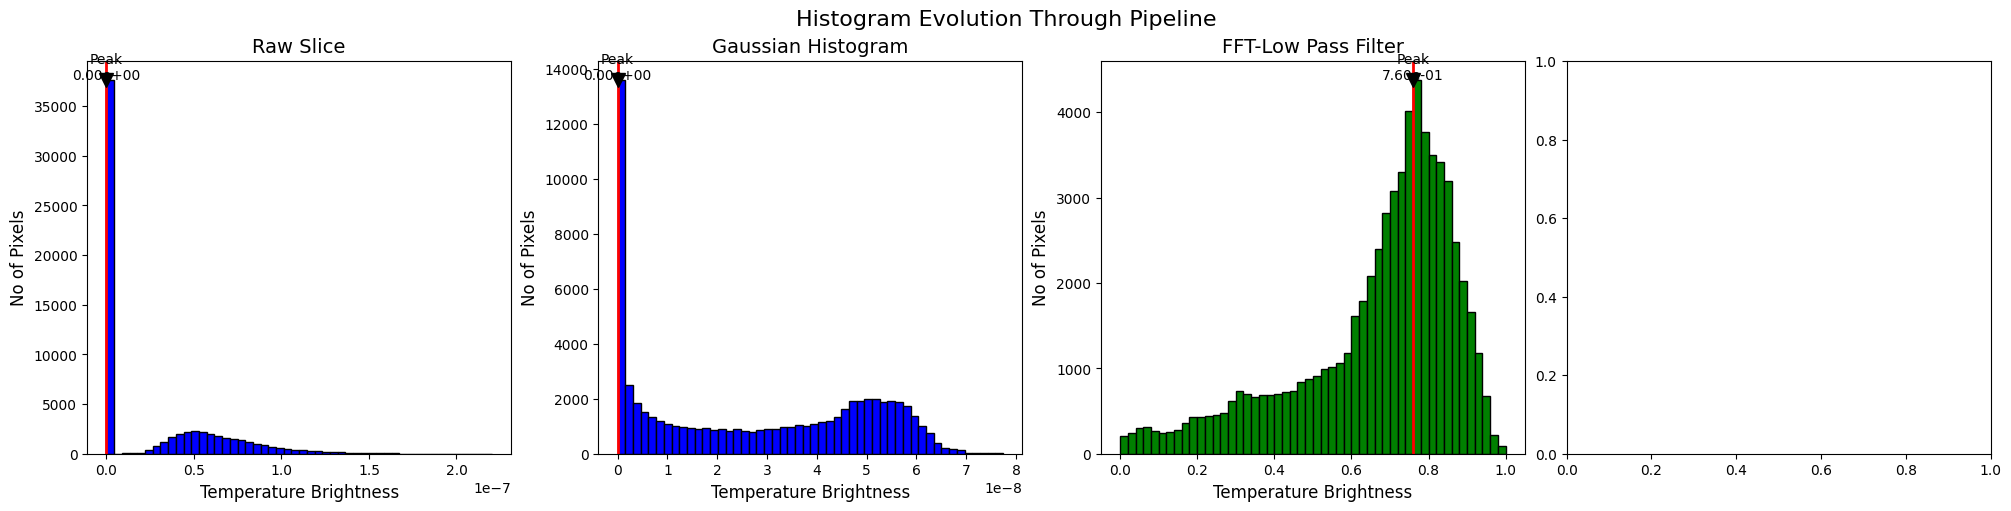

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# === INPUT DATA ===
images = [cosmo_1, smoothed_image, denoised_img_normE2, ]
titles = ['Raw Slice', 'Gaussian Histogram', 'FFT-Low Pass Filter', 'Unsharp Histogram']
colors = ['blue', 'blue', 'green', 'blue']

# === PLOT ===
fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)

for ax, img, title, color in zip(axes, images, titles, colors):
    pixels = img.flatten()

    # Plot histogram
    counts, bins_, _ = ax.hist(pixels, bins=50, color=color, edgecolor='black')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Temperature Brightness", fontsize=12)
    ax.set_ylabel("No of Pixels", fontsize=12)

    # Peak detection
    peak_idx = np.argmax(counts)
    peak_val = bins_[peak_idx]

    # Plot red ▼ at peak
    ax.axvline(peak_val, color='red', linewidth=2)
    ax.plot(peak_val, counts[peak_idx], 'v', color='black', markersize=10)
    ax.text(peak_val, counts[peak_idx] + 5, f"Peak\n{peak_val:.2e}", color='black',
            ha='center', fontsize=10)

plt.suptitle("Histogram Evolution Through Pipeline", fontsize=16)
plt.show()
